Saved: plots/diabetes_expected_performance.pdf


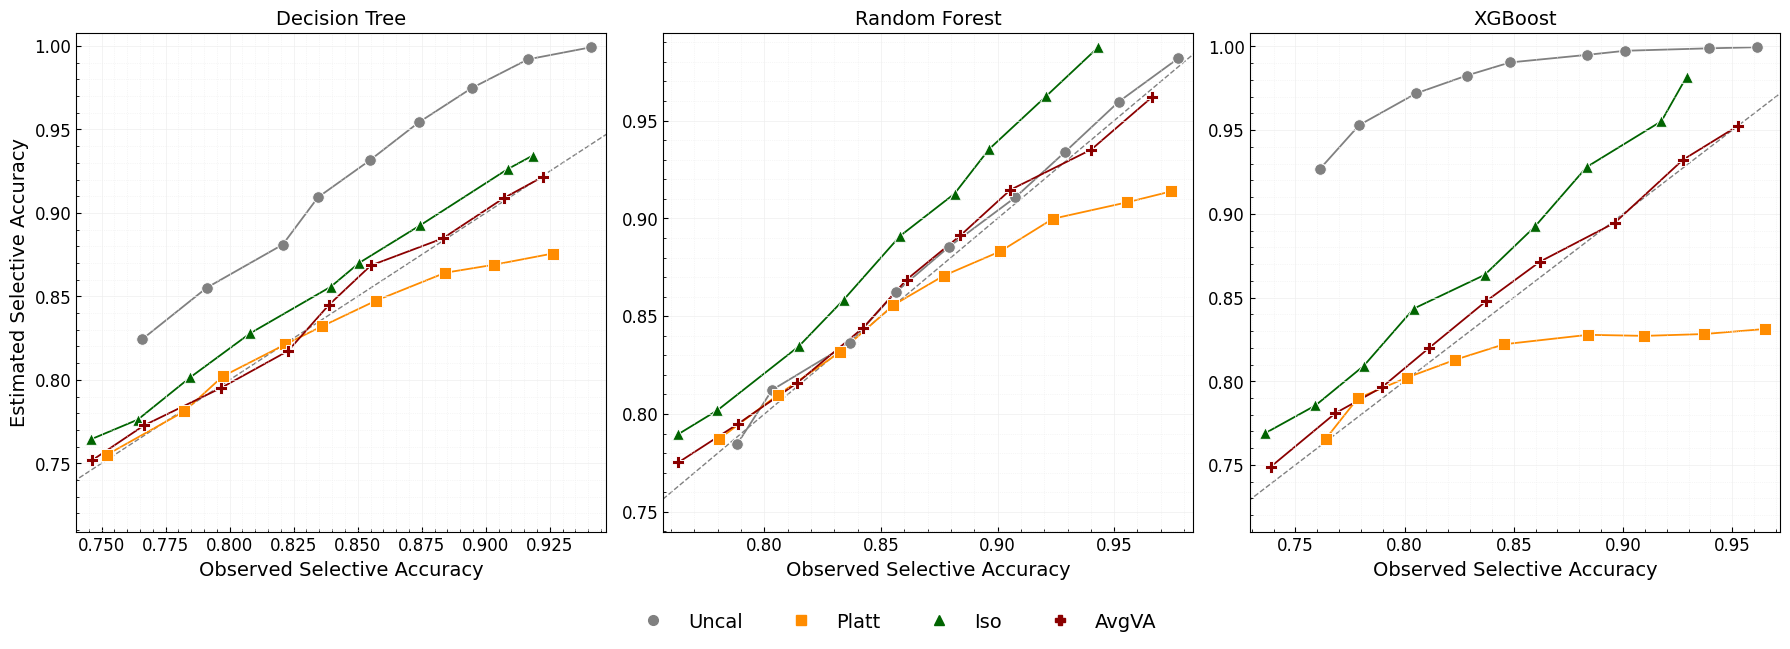

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcdefaults
from matplotlib.lines import Line2D  
import seaborn as sns
import numpy as np

# -------------------- Config --------------------
dataset = "diabetes"         # choose dataset
results_dir = "exp_performance_results"
plots_dir = "plots"
os.makedirs(plots_dir, exist_ok=True)

# Algorithms to plot
ALGOS = [
    ("tree", "Decision Tree"),
    ("rf",    "Random Forest"),
    ("xgb",   "XGBoost"),
]

METHODS = {
    "naive":     ("Uncal", "gray",       "o"),
    "sigmoid":   ("Platt", "darkorange", "s"),
    "isotonic":  ("Iso",   "darkgreen",  "^"),
    "avgva":       ("AvgVA", "darkred",    "P"),
}

# -------------------- Helpers --------------------
def _read_if_exists(path):
    return pd.read_csv(path) if os.path.exists(path) else None

def _collect_frames_for_algo(dataset, algo):
    """Load per-method CSVs for the given dataset+algo and coerce numerics."""
    frames = {}
    for key in METHODS.keys():
        path = os.path.join(results_dir, f"{dataset}_{key}_acc_{algo}.csv")
        df = _read_if_exists(path)
        if df is not None and not df.empty:
            for col in ("accuracy", "estimate", "lower_bound", "upper_bound"):
                if col in df:
                    df[col] = pd.to_numeric(df[col], errors="coerce")
            frames[key] = df.copy()
    return frames

def _compute_limits(frames, methods, pad_frac=0.03):
    """
    Compute independent x and y ranges + global range for y=x line,
    with extra padding (default 3%) for a given algorithm's frames.
    """
    xmins, xmaxs, ymins, ymaxs = [], [], [], []
    for key in methods:
        df = frames.get(key)
        if df is None or df.empty:
            continue
        if "accuracy" in df:
            xmins.append(df["accuracy"].min())
            xmaxs.append(df["accuracy"].max())
        if "estimate" in df:
            ymins.append(df["estimate"].min())
            ymaxs.append(df["estimate"].max())
        if "lower_bound" in df:
            ymins.append(df["lower_bound"].min())
        if "upper_bound" in df:
            ymaxs.append(df["upper_bound"].max())

    if not xmins or not xmaxs or not ymins or not ymaxs:
        return (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)

    xmin, xmax = float(np.min(xmins)), float(np.max(xmaxs))
    ymin, ymax = float(np.min(ymins)), float(np.max(ymaxs))

    xpad = pad_frac * (xmax - xmin if xmax > xmin else 1.0)
    ypad = pad_frac * (ymax - ymin if ymax > ymin else 1.0)

    xlim = (xmin - xpad, xmax + xpad)
    ylim = (ymin - ypad, ymax + ypad)

    diag_min = min(xlim[0], ylim[0])
    diag_max = max(xlim[1], ylim[1])

    return xlim, ylim, (diag_min, diag_max)

# -------------------- Plot --------------------
rcdefaults()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

manual_handles = []
manual_labels = []
for key, (label, color, marker) in METHODS.items():
    handle = Line2D(
        [0], [0],
        marker=marker,
        linestyle="None",
        markersize=7,
        markerfacecolor=color,
        markeredgecolor=color
    )
    manual_handles.append(handle)
    manual_labels.append(label)

for ax, (algo, panel_title) in zip(axes, ALGOS):
    ax.set_title(panel_title, fontsize=14)
    ax.set_xlabel("Observed Selective Accuracy", fontsize=14)

    ax.set_ylabel("Estimated Selective Accuracy", fontsize=14)

    ax.grid(which="major", axis="both", color="#EEEEEE", linestyle="solid", linewidth=0.5)
    ax.grid(which="minor", axis="both", color="#EEEEEE", linestyle="dotted", linewidth=0.5)
    ax.minorticks_on()
    ax.tick_params(direction="in", which="both", axis="both", labelsize=12)

    frames = _collect_frames_for_algo(dataset, algo)
    methods_all = list(METHODS.keys())

    xlim, ylim, diag_range = _compute_limits(frames, methods_all, pad_frac=0.03)

    plotted_any = False

    for key in methods_all:
        label, color, marker = METHODS[key]
        df = frames.get(key)
        if df is None or df.empty:
            continue

        df_plot = df.dropna(subset=["accuracy", "estimate"])
        if df_plot.empty:
            continue

        sns.lineplot(
            data=df_plot,
            x="accuracy",
            y="estimate",
            ax=ax,
            linewidth=1.3,
            color=color,
            zorder=1,
            estimator=None,
            sort=False
        )

        sns.scatterplot(
            data=df_plot,
            x="accuracy",
            y="estimate",
            s=70,
            ax=ax,
            color=color,
            marker=marker,
            zorder=3,
            label=None
        )

        plotted_any = True

    if plotted_any:
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.plot(
            [diag_range[0], diag_range[1]],
            [diag_range[0], diag_range[1]],
            ls="--",
            c="gray",
            lw=1,
            zorder=0
        )
    else:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)

    leg = ax.get_legend()
    if leg:
        leg.remove()

fig.legend(
    manual_handles, manual_labels,
    fontsize=14,
    loc="upper center",
    bbox_to_anchor=(0.5, 0),
    ncol=len(manual_labels),
    frameon=False
)

axes[1].set_ylabel("")
axes[2].set_ylabel("")

plt.tight_layout()

# Save
out_path = os.path.join(plots_dir, f"{dataset}_expected_performance.pdf")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
print(f"Saved: {out_path}")

Saved: plots/intervals_vs_rejection_rate_realacc_2rows_3cols_bottomlegend.pdf


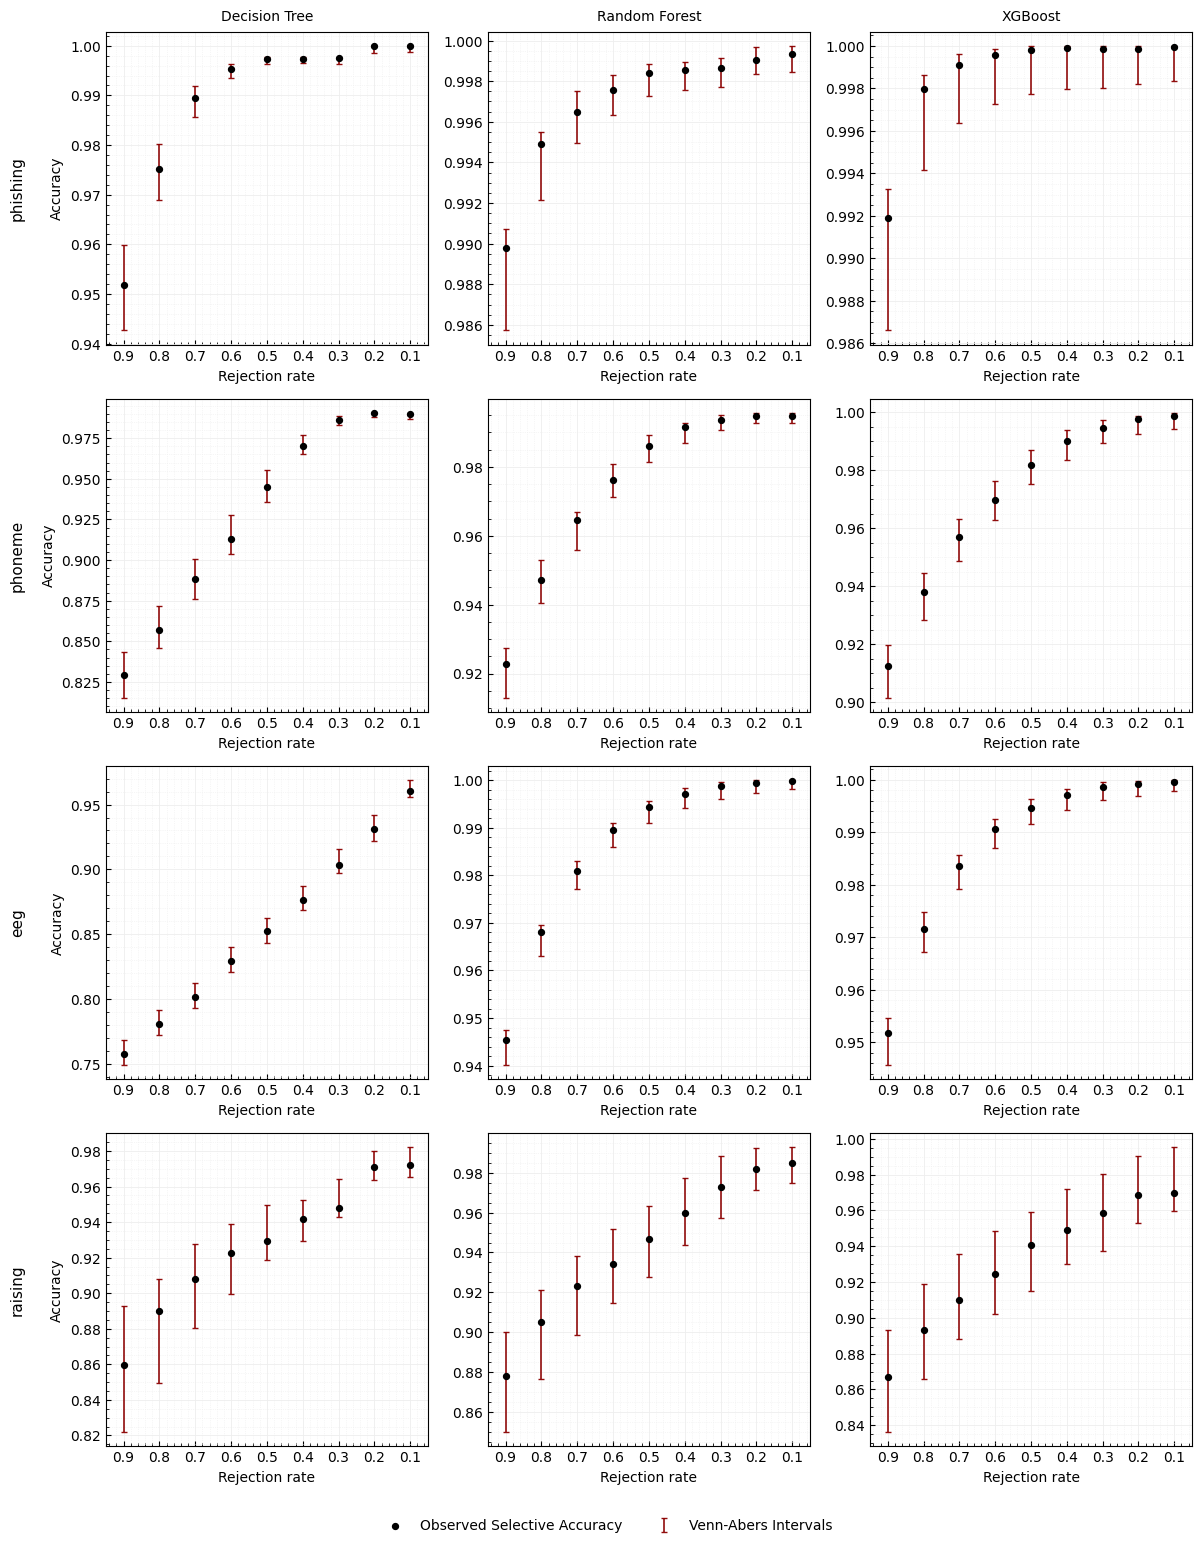

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcdefaults

# ------------- Config -------------
datasets = ["phishing", "phoneme", "eeg", "raising"]
results_dir = "exp_performance_results"
plots_dir = "plots"
os.makedirs(plots_dir, exist_ok=True)

# Columns = algorithms
ALGO_PANEL = [("tree", "Decision Tree"), ("rf", "Random Forest"), ("xgb", "XGBoost")]

# Your files store "top certain predictions" (coverage kept), but you want to DISPLAY rejection rate.
X_MIN, X_MAX = 0.05, 0.95
X_TICKS = np.round(np.arange(0.1, 1.0, 0.1), 1)  # positions: 0.1..0.9


# Style
VA2_COLOR = "darkred"
ELINEWIDTH = 1.2
CAPSIZE = 2
ALPHA = 0.95

REAL_COLOR = "black"
REAL_POINT_SIZE = 18

# ------------- Helpers -------------
def read_df(dataset: str, algo: str) -> pd.DataFrame:
    path = os.path.join(results_dir, f"{dataset}_avgva_{algo}.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path)

    required = {"rejection_rate", "lower_bound", "upper_bound", "accuracy"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path} missing columns: {sorted(missing)}")

    # Use estimate if present; otherwise midpoint (needed only to center errorbar)
    if "estimate" not in df.columns:
        df["estimate"] = (df["lower_bound"] + df["upper_bound"]) / 2.0

    df = df[["rejection_rate", "accuracy", "estimate", "lower_bound", "upper_bound"]].copy()
    for c in ["rejection_rate", "accuracy", "estimate", "lower_bound", "upper_bound"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["rejection_rate", "accuracy", "estimate", "lower_bound", "upper_bound"])

    return df


def mean_on_grid(df: pd.DataFrame, grid: np.ndarray) -> pd.DataFrame:
    """
    Average duplicates at identical top_certain (multiple runs).
    If values are slightly off-grid, interpolate to the requested grid.
    """
    g = (df.groupby("rejection_rate", as_index=False)
           .agg(accuracy=("accuracy", "mean"),
                estimate=("estimate", "mean"),
                lower_bound=("lower_bound", "mean"),
                upper_bound=("upper_bound", "mean"))
           .sort_values("rejection_rate"))

    x = g["rejection_rate"].to_numpy()
    acc = g["accuracy"].to_numpy()
    est = g["estimate"].to_numpy()
    lo = g["lower_bound"].to_numpy()
    hi = g["upper_bound"].to_numpy()

    out = pd.DataFrame({"rejection_rate": grid})
    out["accuracy"] = np.nan
    out["estimate"] = np.nan
    out["lower_bound"] = np.nan
    out["upper_bound"] = np.nan

    if len(x) == 0:
        return out

    mask = (grid >= x.min()) & (grid <= x.max())
    out.loc[mask, "accuracy"] = np.interp(grid[mask], x, acc)
    out.loc[mask, "estimate"] = np.interp(grid[mask], x, est)
    out.loc[mask, "lower_bound"] = np.interp(grid[mask], x, lo)
    out.loc[mask, "upper_bound"] = np.interp(grid[mask], x, hi)
    return out


# ------------- Load per-dataset/per-algo data -------------
frames = {}
for ds in datasets:
    for algo, _ in ALGO_PANEL:
        try:
            df = read_df(ds, algo)
            df_grid = mean_on_grid(df, X_TICKS)  # grid in top_certain space
            frames[(ds, algo)] = df_grid
        except (FileNotFoundError, ValueError) as e:
            print(e)
            frames[(ds, algo)] = None

# ------------- Plot: rows = datasets, cols = algorithms -------------
rcdefaults()
n_rows = len(datasets)
n_cols = len(ALGO_PANEL)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 3.8 * n_rows),
    sharex=False,
    sharey=False
)

# Ensure axes is 2D if n_rows == 1
if n_rows == 1:
    axes = np.array([axes])

# Tick labels should show rejection rate = 1 - top_certain, but reversed order
tick_labels_rejection = [f"{(1 - t):.1f}" for t in X_TICKS]

# We'll store handles from the first subplot and put the legend at the bottom center
legend_handles = None
legend_labels = ["Observed Selective Accuracy", "Venn-Abers Intervals"]

for i, ds in enumerate(datasets):
    for j, (algo, col_title) in enumerate(ALGO_PANEL):
        ax = axes[i, j]
        df = frames.get((ds, algo))

        ax.grid(which="major", axis="both", color="#EEEEEE", linestyle="solid", linewidth=0.6)
        ax.grid(which="minor", axis="both", color="#EEEEEE", linestyle="dotted", linewidth=0.5)
        ax.minorticks_on()
        ax.tick_params(direction="in", which="both", axis="both", labelsize=10)

        # Column titles on top row only
        if i == 0:
            ax.set_title(col_title, fontsize=10, pad=8)

        # Labels
        ax.set_xlabel("Rejection rate", fontsize=10)
        if j == 0:
            ax.set_ylabel("Accuracy", fontsize=10)

        # Row label (dataset) in the left margin of the first column
        if j == 0:
            ax.text(-0.25, 0.5, ds, va="center", ha="right", rotation=90,
                    transform=ax.transAxes, fontsize=11)

        # X axis span + reversed direction (0.9 left, 0.1 right)
        ax.set_xlim(X_MIN, X_MAX)
        ax.set_xticks(X_TICKS)                       # tick positions in top_certain space
        ax.set_xticklabels(tick_labels_rejection)        # show rejection-rate labels
        #ax.invert_xaxis()

        if df is not None and not df.empty:
            dfp = df.sort_values("rejection_rate", ascending=True)  # match inverted x-axis

            x = dfp["rejection_rate"].to_numpy()

            # Venn-Abers intervals (darkred errorbars, no center marker)
            y = dfp["estimate"].to_numpy()
            lo = dfp["lower_bound"].to_numpy()
            hi = dfp["upper_bound"].to_numpy()
            yerr = np.vstack([y - lo, hi - y])

            eb = ax.errorbar(
                x, y, yerr=yerr,
                fmt="none",
                ecolor=VA2_COLOR,
                elinewidth=ELINEWIDTH,
                capsize=CAPSIZE,
                alpha=ALPHA,
                zorder=2
            )

            # Observed selective accuracy (black dots)
            sc = ax.scatter(
                x, dfp["accuracy"].to_numpy(),
                s=REAL_POINT_SIZE,
                color=REAL_COLOR,
                zorder=3
            )

            # Save handles from first subplot only
            if i == 0 and j == 0:
                legend_handles = [sc, eb]

# Figure-level legend: bottom center, no box, centered under middle column
if legend_handles is not None:
    fig.legend(
        legend_handles,
        legend_labels,
        loc="lower center",
        ncol=2,
        frameon=False,
        fontsize=10,
        bbox_to_anchor=(0.5, -0.02)
    )

# Leave space for legend at bottom
plt.tight_layout(rect=[0, 0.01, 1, 1])

outfile = os.path.join(plots_dir, "intervals_vs_rejection_rate_realacc_2rows_3cols_bottomlegend.pdf")
plt.savefig(outfile, dpi=300, bbox_inches="tight")
print(f"Saved: {outfile}")
plt.show()
